In [1]:

from google.colab import auth
auth.authenticate_user()

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# https://arxiv.org/pdf/1505.00387


class HighwayLayer(nn.Module):
    def __init__(self,
            features_amount: int,
            activation_function=F.relu,
            bias: float=-3.0
        ):
        super().__init__()
        self.activation = activation_function
        # Amount of neurons has to be same as amount of features, as from paper: dimensionality of x, y, H(x, WH) and T (x, WT) must be the same for Equation (3) to be valid
        # H(x) = activation(W_H x + b_H)
        self.weights_hidden = nn.Linear( # This is affine transform, aka multiply by matrix and add vector
            features_amount,
            features_amount
        )
        # T(x) = sigmoid(W_T x + b_T)
        self.weights_transform = nn.Linear(
            features_amount,
            features_amount
        )
        # Paper suggests to initialize biases as vectors with same negative values in each cell
        # This encourages the network to initially carry information rather than transform it
        nn.init.constant_(
            self.weights_transform.bias,
            bias
        )

    def forward(self, inputs): # inputs: (samples_amount, features_amount) -> caches
        H = self.activation(self.weights_hidden(inputs)) # From paper: H is usually an affine transform (multiply by a matrix, add vector) followed by a non-linear activation function, but in general it may take other forms
        T = torch.sigmoid(self.weights_transform(inputs)) # From paper: T(x) = sigma(W^T x + b), sigma(x) = 1 / (1 + e**(-x)) https://docs.pytorch.org/docs/2.14/generated/torch.nn.Sigmoid.html
        # From paper: y = H(x, W) * T(x, W) + x*(1 - T(x, W))
        # because there C = 1 − T
        # otherwise carry gate can be different
        return H * T + inputs * (1 - T) # H * T transformed, inputs * (1 - T) unchanged, because T is between 0 and 1 those are exclusive, so either it transforms or passes, depending on if T is close to 1 at certain cell


class HighwayNetwork(nn.Module):
    def __init__(self,
        input_size: int,
        hidden_size: int,
        output_size: int,
        layers_amount: int,
        activation_function=F.relu,
        bias: int=-3
    ):
        super().__init__()
        self.activation = activation_function
        # Plain layer: change dimensionality from input_size to hidden_size
        self.input_projection = nn.Linear( # Just affine transform
            input_size,
            hidden_size
        )
        # Highway layers: preserve dimensionality as hidden_size
        self.layers = nn.ModuleList([
            HighwayLayer(
                features_amount=hidden_size,
                activation_function=activation_function,
                bias=bias
            )
            for _ in range(layers_amount)
        ])
        # Plain layer: change dimensionality from hidden_size to output_size
        self.output_projection = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, inputs):
        current = self.activation(self.input_projection(inputs))
        for layer in self.layers:
            current = layer(current)
        # From paper: In cases when it is desirable to change the size of the representation, one can replace x with ˆx obtained by suitably sub-sampling or zero-padding x. Another alternative is to use a plain layer (without highways) to change dimensionality and then continue with stacking highway layers
        final = self.output_projection(current)
        return final

In [4]:
import torch
from torch.utils.data import TensorDataset, DataLoader, random_split

import pickle
import numpy as np


def unpickle(file_path: str):
    # From here https://cave.cs.toronto.edu/kriz/cifar.html
    obtained = None
    with open(file_path, "rb") as file:
        obtained = pickle.load(file, encoding="bytes")
    return obtained


drive_path = "/content/drive/MyDrive/highway_network"

cifar_train_batches = [unpickle(f"{drive_path}/cifar-10-batches-py/data_batch_{i}") for i in range(1, 6)] # [{"data": ..., "labels": ...}]
cifar_test_batch = unpickle(f"{drive_path}/cifar-10-batches-py/test_batch")
# data - a 10000x3072 numpy array of uint8s. Each row of the array stores a 32x32 colour image. The first 1024 entries contain the red channel values, the next 1024 the green, and the final 1024 the blue. The image is stored in row-major order, so that the first 32 entries of the array are the red channel values of the first row of the image.
# labels - a list of 10000 numbers in the range 0-9. The number at index i indicates the label of the ith image in the array data.
# https://cave.cs.toronto.edu/kriz/cifar.html
cifar_labels = unpickle(f"{drive_path}/cifar-10-batches-py/batches.meta")

# Combine the five training batches
X_train = torch.tensor(
    np.concatenate(
        [batch[b"data"] for batch in cifar_train_batches],
        axis=0
    ),
    dtype=torch.float32
)
# Test part
X_test = torch.tensor(
    cifar_test_batch[b"data"],
    dtype=torch.float32
)

# Supervised learning, so labels
y_train = torch.tensor(
    sum([batch[b"labels"] for batch in cifar_train_batches], []),
    dtype=torch.long
)
# Test part
y_test = torch.tensor(
    cifar_test_batch[b"labels"],
    dtype=torch.long
)

# Normalize pixel values to [0, 1] to avoid bad conditioning
X_train /= 255.0
X_test /= 255.0

# Reshape flattened images into (N, C, H, W) for normalization (amount of images, amount of color channels, height of an image, width of an image)
X_train = X_train.reshape(-1, 3, 32, 32)
# Test part, using same normalizations from training set to not leak data
X_test = X_test.reshape(-1, 3, 32, 32)

# Channel-wise normalization
mean = X_train.mean(dim=(0, 2, 3))
std = X_train.std(dim=(0, 2, 3))

# Normalize using mean and stddev
X_train = (
    X_train - mean.reshape(1, 3, 1, 1)
) / std.reshape(1, 3, 1, 1)
# Test part, using same normalizations from training set to not leak data
X_test = (
    X_test - mean.reshape(1, 3, 1, 1)
) / std.reshape(1, 3, 1, 1)

# Flatten again for the fully connected network
X_train = X_train.reshape(-1, 3072)
# Test part
X_test = X_test.reshape(-1, 3072)

# Test and train datasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)

# Split training dataset into training and validation datasets
validation_size = int(0.1 * len(train_dataset))
training_size = len(train_dataset) - validation_size

train_subset, validation_subset = random_split(
    train_dataset,
    [training_size, validation_size],
    generator=torch.Generator().manual_seed(10112026)
)

# DataLoaders
batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=torch.cuda.is_available()
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=torch.cuda.is_available()
)
print("Training samples:", len(train_subset))
print("Validation samples:", len(validation_subset))
print("Test samples:", len(test_dataset))

Training samples: 45000
Validation samples: 5000
Test samples: 10000


In [5]:
import torch

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Zero old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        total_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


@torch.no_grad() # This does not require bookkeeping of gradients
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        total_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy

In [6]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

GPU Available: True
Device Name: Tesla T4


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HighwayNetwork(
    input_size=3072, # As in input, 32*32*3 (32x32 images with 3 channels from RGB)
    hidden_size=256,
    output_size=10, # 10 categories
    layers_amount=4,
    activation_function=F.relu, # Most commonly used
    bias=-3.0 # As in paper
).to(device)

print(model)
print("Device:", device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-2
)

epochs = 100

history = {
    "train_loss": [],
    "train_accuracy": [],
    "validation_loss": [],
    "validation_accuracy": []
}

best_validation_loss = float("inf")
patience = 20
epochs_without_improvement = 0

for epoch in range(epochs):

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    validation_loss, validation_accuracy = evaluate(
        model, validation_loader, criterion, device
    )

    if validation_loss < best_validation_loss:
        best_validation_loss = validation_loss
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "validation_loss": best_validation_loss
        }, "/content/drive/MyDrive/highway_network/highway_checkpoint.pth")
        print("Model checkpoint saved")
    else:
        epochs_without_improvement += 1

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)

    history["validation_loss"].append(validation_loss)
    history["validation_accuracy"].append(validation_accuracy)

    print(
        f"Epoch [{epoch + 1}/{epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Accuracy: {train_accuracy:.2%} "
        f"| Validation Loss: {validation_loss:.4f} "
        f"| Validation Accuracy: {validation_accuracy:.2%}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

checkpoint = torch.load(
    "/content/drive/MyDrive/highway_network/highway_checkpoint.pth",
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])

test_loss, test_accuracy = evaluate(
    model,
    test_loader,
    criterion,
    device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

HighwayNetwork(
  (input_projection): Linear(in_features=3072, out_features=256, bias=True)
  (layers): ModuleList(
    (0-3): 4 x HighwayLayer(
      (weights_hidden): Linear(in_features=256, out_features=256, bias=True)
      (weights_transform): Linear(in_features=256, out_features=256, bias=True)
    )
  )
  (output_projection): Linear(in_features=256, out_features=10, bias=True)
)
Device: cuda
Model checkpoint saved
Epoch [1/100] | Train Loss: 1.6118 | Train Accuracy: 42.74% | Validation Loss: 1.4837 | Validation Accuracy: 47.68%
Model checkpoint saved
Epoch [2/100] | Train Loss: 1.3758 | Train Accuracy: 51.20% | Validation Loss: 1.4306 | Validation Accuracy: 48.94%
Model checkpoint saved
Epoch [3/100] | Train Loss: 1.2659 | Train Accuracy: 55.02% | Validation Loss: 1.4128 | Validation Accuracy: 50.88%
Model checkpoint saved
Epoch [4/100] | Train Loss: 1.1828 | Train Accuracy: 57.89% | Validation Loss: 1.4107 | Validation Accuracy: 50.40%
Epoch [5/100] | Train Loss: 1.1167 | Train

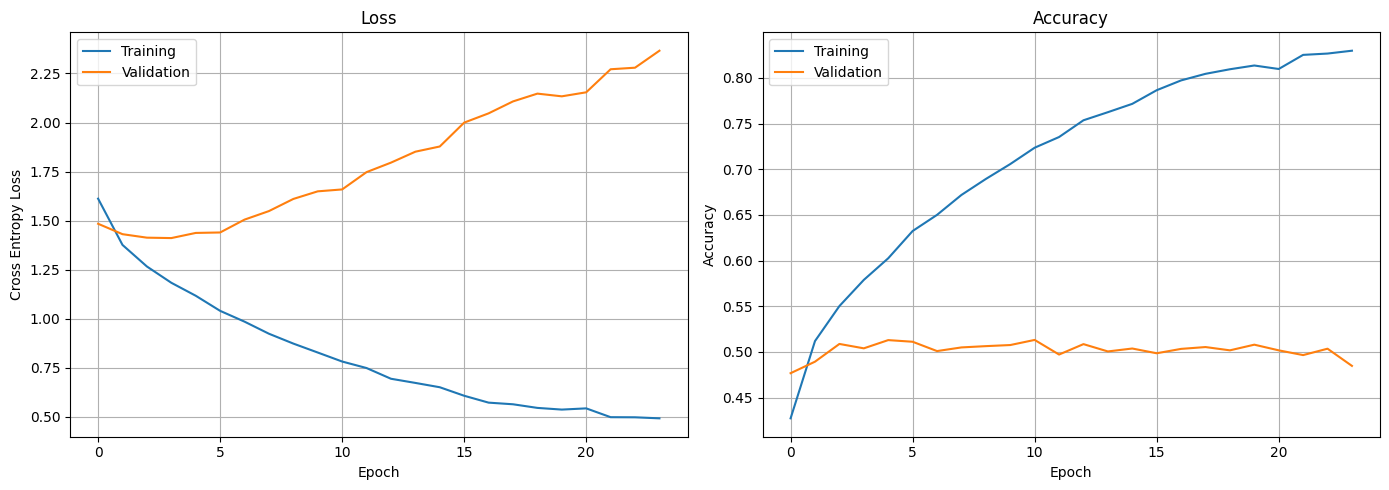

In [8]:
# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history["train_loss"], label="Training")
axes[0].plot(history["validation_loss"], label="Validation")

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross Entropy Loss")
axes[0].legend()
axes[0].grid()

# Accuracy
axes[1].plot(history["train_accuracy"], label="Training")
axes[1].plot(history["validation_accuracy"], label="Validation")

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

In [9]:
class ConvHighwayLayer(nn.Module):
    def __init__(self, channels: int, kernel_size: int = 3,
                 activation=F.relu, bias: float = -3.0):
        super().__init__()
        padding = kernel_size // 2          # same spatial size

        # H(x) = activation(Conv(x))
        self.conv_H = nn.Conv2d(channels, channels, kernel_size,
                                padding=padding, bias=True)

        # T(x) = sigmoid(Conv(x))
        self.conv_T = nn.Conv2d(channels, channels, kernel_size,
                                padding=padding, bias=True)

        # Negative bias on the transform gate (paper recommendation)
        nn.init.constant_(self.conv_T.bias, bias)

        self.activation = activation

    def forward(self, x):
        H = self.activation(self.conv_H(x))
        T = torch.sigmoid(self.conv_T(x))
        return H * T + x * (1 - T)

class ConvHighwayNetwork(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),          # 16×16
        )

        self.highway_blocks = nn.ModuleList([
            ConvHighwayLayer(64) for _ in range(6)
        ])

        self.downsample = nn.Sequential(  # optional further reduction
            nn.Conv2d(64, 128, 3, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
        )

        self.highway_blocks2 = nn.ModuleList([
            ConvHighwayLayer(128) for _ in range(4)
        ])

        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.stem(x)
        for layer in self.highway_blocks:
            x = layer(x)
        x = self.downsample(x)
        for layer in self.highway_blocks2:
            x = layer(x)
        return self.head(x)

In [10]:
# This is required because earlier there was final flatten
X_train = X_train.reshape(-1, 3, 32, 32)
X_test  = X_test.reshape(-1, 3, 32, 32)

train_dataset = TensorDataset(X_train, y_train)
test_dataset  = TensorDataset(X_test,  y_test)

validation_size = int(0.1 * len(train_dataset))
training_size   = len(train_dataset) - validation_size
train_subset, validation_subset = random_split(
    train_dataset,
    [training_size, validation_size],
    generator=torch.Generator().manual_seed(10112026)
)

batch_size = 128
train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True,
                          pin_memory=torch.cuda.is_available())
validation_loader = DataLoader(validation_subset, batch_size=batch_size, shuffle=False,
                               pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False,
                         pin_memory=torch.cuda.is_available())

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ConvHighwayNetwork(num_classes=10).to(device)
print(model)
print("Device:", device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

epochs = 100
history = {
    "train_loss": [], "train_accuracy": [],
    "validation_loss": [], "validation_accuracy": []
}

best_validation_loss = float("inf")
patience = 20
epochs_without_improvement = 0

for epoch in range(epochs):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )
    val_loss, val_acc = evaluate(
        model, validation_loader, criterion, device
    )

    if val_loss < best_validation_loss:
        best_validation_loss = val_loss
        epochs_without_improvement = 0
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "validation_loss": best_validation_loss
        }, "/content/drive/MyDrive/highway_network/conv_highway_checkpoint.pth")
        print("Model checkpoint saved")
    else:
        epochs_without_improvement += 1

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_acc)
    history["validation_loss"].append(val_loss)
    history["validation_accuracy"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2%} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2%}"
    )

    if epochs_without_improvement >= patience:
        print("Early stopping")
        break

# Load best checkpoint and evaluate on test set
checkpoint = torch.load(
    "/content/drive/MyDrive/highway_network/conv_highway_checkpoint.pth",
    map_location=device, weights_only=True
)
model.load_state_dict(checkpoint["model_state_dict"])

test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2%}")

ConvHighwayNetwork(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (highway_blocks): ModuleList(
    (0-5): 6 x ConvHighwayLayer(
      (conv_H): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (conv_T): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    )
  )
  (downsample): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
  )
  (highway_blocks2): Modu

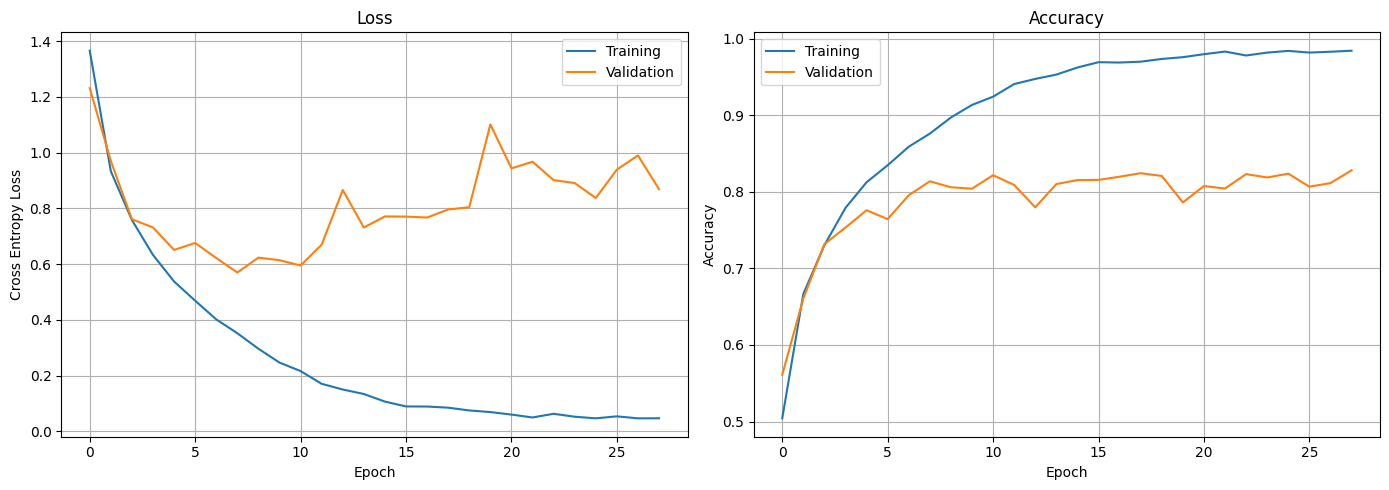

In [12]:
# Plotting
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(history["train_loss"], label="Training")
axes[0].plot(history["validation_loss"], label="Validation")

axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross Entropy Loss")
axes[0].legend()
axes[0].grid()

# Accuracy
axes[1].plot(history["train_accuracy"], label="Training")
axes[1].plot(history["validation_accuracy"], label="Validation")

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()